# Исследование пользовательской активности на сервисе Яндекс Афиша осенью 2024 года


## Цели и задачи проекта
**Цели**:

- Выявить изменения в предпочтениях пользователей и популярности событий осенью 2024 года по сравнению с летом.
- Проверить гипотезы о различиях в поведении пользователей мобильных и стационарных устройств.

**Задачи**:

1. Загрузить данные и оценить их качество
2. Провести предобработку
3. Исследовать сезонные изменения, активность пользователей, регионы и партнёров
4. Проверить статистические гипотезы
5. Сформулировать выводы и рекомендации

### Описание данных

Данные состоят из трех датасетов:

Датасет `final_tickets_orders_df.csv` включает информацию обо всех заказах билетов, совершённых с двух типов устройств — мобильных и стационарных. 
- `order_id` — уникальный идентификатор заказа.
- `user_id` — уникальный идентификатор пользователя.
- `created_dt_msk` — дата создания заказа (московское время).
- `created_ts_msk` — дата и время создания заказа (московское время).
- `event_id` — идентификатор мероприятия из таблицы events.
- `cinema_circuit` — сеть кинотеатров. Если не применимо, то здесь будет значение 'нет'.
- `age_limit` — возрастное ограничение мероприятия.
- `currency_code` — валюта оплаты, например `rub` для российских рублей.
- `device_type_canonical` — тип устройства, с которого был оформлен заказ, например `mobile` для мобильных устройств, `desktop` для стационарных.
- `revenue` — выручка от заказа.
- `service_name` — название билетного оператора.
- `tickets_count` — количество купленных билетов.
- `total` — общая сумма заказа.
- `days_since_prev` — количество дней с предыдущей покупки для каждого пользователя. Если покупки не было, то данные содержат пропуск.

Датасет `final_tickets_events_df.csv` содержит информацию о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия. 
- `event_id` — уникальный идентификатор мероприятия.
- `event_name` — название мероприятия. Аналог поля event_name_code из исходной базы данных.
- `event_type_description` — описание типа мероприятия.
- `event_type_main` — основной тип мероприятия: театральная постановка, концерт и так далее.
- `organizers` — организаторы мероприятия.
- `region_name` — название региона.
- `city_name` — название города.
- `venue_id` — уникальный идентификатор площадки.
- `venue_name` — название площадки.
- `venue_address` — адрес площадки.

Датасет `final_tickets_tenge_df.csv` с информацией о курсе тенге к российскому рублю за 2024 год. Значения в рублях представлены для 100 тенге. Датасет содержит такие поля:
- `nominal` — номинал (100 тенге).
- `data` — дата.
- `curs` — курс тенге к рублю.
- `cdx` — обозначение валюты (kzt).

### Содержимое проекта

1. Цели и задачи проекта
2. Загрузка данных и знакомство с ними
3. Предобработка данных
4. Исследовательский анализ данных
 - Сезонные изменения заказов
 - Осенняя активность пользователей
 - Популярные события и партнёры
5. Статистический анализ данных
6. Общий вывод и рекомендации

## Загрузка данных и знакомство с ними

Начнём с загрузки библиотек и датасетов `final_tickets_orders_df.csv`, `final_tickets_events_df.csv` и `final_tickets_tenge_df.csv`. Будем использовать `pandas` и библиотеки визуализации данных `matplotlib` и `seaborn`, а также `scipy`. Данные датасетов сохраним в переменных:` tickets_orders_df`,`tickets_events_df` и  `tickets_tenge_df`.

In [1]:
# Загружаем библиотеки 
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# Выгружаем данные в переменные tickets_orders_df, tickets_events_df и tickets_tenge_df.
tickets_orders_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_orders_df.csv')
tickets_events_df=pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_events_df.csv')
tickets_tenge_df=pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')

Познакомимся с данными датасета `tickets_orders_df` — выведем первые строки методом `head()`, а информацию о датафрейме методом `info()`:

In [3]:
# Выводим первые строки датафрейма на экран
tickets_orders_df.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


In [4]:
# Выводим информацию о датафрейме
tickets_orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

Датасет `tickets_orders_df` содержит 290 849 строк и 14 столбцов с информацией о заказах билетов. Типы данных в большинстве столбцов соответствуют содержанию: четыре столбца имеют тип `int64`, три — `float64`, семь — `object`. Исключение — столбцы `created_dt_msk` и `created_ts_msk`: они хранят даты, но имеют тип `object`, поэтому на этапе предобработки их нужно перевести в datetime с помощью `pd.to_datetime()`. Пропуски есть только в `days_since_prev` (21 940 значений), что соответствует первым покупкам пользователей, в остальных столбцах пропусков нет.

Познакомимся с данными датасета `tickets_events_df` — выведем первые строки методом `head()`, а информацию о датафрейме методом `info()`:

In [5]:
# Выводим первые строки датафрейма на экран
tickets_events_df.head()

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


In [6]:
# Выводим информацию о датафрейме
tickets_events_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


Датасет `tickets_events_df` содержит 22 427 строк и 11 столбцов с информацией о мероприятиях, площадках и регионах. Типы данных соответствуют содержанию: три столбца имеют тип `int64`, восемь — `object`. Пропусков в данных нет. В датасете есть столбец `city_id`, которого нет в описании данных.

Такими же методами посмотрим данные датасета `tickets_tenge_df`.

In [7]:
# Выводим первые строки датафрейма на экран
tickets_tenge_df.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [8]:
# Выводим информацию о датафрейме
tickets_tenge_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


Датасет `tickets_tenge_df` содержит 357 строк и 4 столбца с информацией о курсе тенге к российскому рублю. В трёх столбцах типы данных соответствуют содержанию. Исключение — столбец data: он хранит дату, но имеет тип `object`, поэтому на этапе предобработки его нужно перевести в `datetime` с помощью `pd.to_datetime()`. Пропусков в данных нет.

Промежуточный вывод. Загружены три датасета: `tickets_orders_df` (290 849 строк, 14 столбцов), `tickets_events_df` (22 427 строки, 11 столбцов) и `tickets_tenge_df` (357 строк, 4 столбца). Данные в целом соответствуют описанию, кроме лишнего столбца `city_id` в `tickets_events_df`. Пропуски есть только в `days_since_prev` (21 940 значений, первые покупки пользователей). На предобработке нужно: преобразовать столбцы с датами в `datetime`, уменьшить разрядность числовых типов, проверить категории, выбросы и дубликаты, объединить датафреймы и привести выручку к рублям.

## Предобработка данных и подготовка их к исследованию

Посмотрим на количество пропущенных значений по столбцам датафреймов.

In [9]:
# Выводим количество пропущенных значений в датафрейме
tickets_orders_df.isna().sum()

order_id                     0
user_id                      0
created_dt_msk               0
created_ts_msk               0
event_id                     0
cinema_circuit               0
age_limit                    0
currency_code                0
device_type_canonical        0
revenue                      0
service_name                 0
tickets_count                0
total                        0
days_since_prev          21940
dtype: int64

In [10]:
# Выводим количество пропущенных значений в датафрейме
tickets_events_df.isna().sum()

event_id                  0
event_name                0
event_type_description    0
event_type_main           0
organizers                0
region_name               0
city_name                 0
city_id                   0
venue_id                  0
venue_name                0
venue_address             0
dtype: int64

In [11]:
# Выводим количество пропущенных значений в датафрейме
tickets_tenge_df.isna().sum()

data       0
nominal    0
curs       0
cdx        0
dtype: int64

Пропуски есть только в `days_since_prev` (21 940 значений, около 7,5%), это первые покупки пользователей. Остальные столбцы пропусков не содержат, выгрузка прошла корректно. Пропуски не заполняем: нулевое значение исказило бы смысл «дней с предыдущей покупки».

Изучим значения в ключевых столбцах, для категориальных значений посмотрим, какие категории присутствуют в данных.

In [12]:
# Создаем список нужных колонок
columns_to_check = [
    'cinema_circuit', 
    'age_limit', 
    'currency_code', 
    'device_type_canonical', 
    'service_name'
]

for col in columns_to_check:
    print(f"\n РАСПРЕДЕЛЕНИЕ ЗНАЧЕНИЙ ДЛЯ СТОЛБЦА: {col} ")
    # dropna=False, чтобы увидеть явные NaN пропуски
    print(tickets_orders_df[col].value_counts(dropna=False))
    print("-" * 60)




 РАСПРЕДЕЛЕНИЕ ЗНАЧЕНИЙ ДЛЯ СТОЛБЦА: cinema_circuit 
нет           289451
Другое          1261
КиноСити         122
Москино            7
Киномакс           7
ЦентрФильм         1
Name: cinema_circuit, dtype: int64
------------------------------------------------------------

 РАСПРЕДЕЛЕНИЕ ЗНАЧЕНИЙ ДЛЯ СТОЛБЦА: age_limit 
16    78579
12    62557
0     61487
6     52173
18    36053
Name: age_limit, dtype: int64
------------------------------------------------------------

 РАСПРЕДЕЛЕНИЕ ЗНАЧЕНИЙ ДЛЯ СТОЛБЦА: currency_code 
rub    285780
kzt      5069
Name: currency_code, dtype: int64
------------------------------------------------------------

 РАСПРЕДЕЛЕНИЕ ЗНАЧЕНИЙ ДЛЯ СТОЛБЦА: device_type_canonical 
mobile     232679
desktop     58170
Name: device_type_canonical, dtype: int64
------------------------------------------------------------

 РАСПРЕДЕЛЕНИЕ ЗНАЧЕНИЙ ДЛЯ СТОЛБЦА: service_name 
Билеты без проблем        63709
Лови билет!               41126
Билеты в руки             40364


In [13]:
for col in columns_to_check: 
    # Количество значений как есть сейчас (переводим в str, чтобы не упасть на числах)
    count_before = tickets_orders_df[col].astype(str).nunique()
    
    # Количество значений ПОСЛЕ удаления пробелов и приведения к нижнему регистру
    count_after = tickets_orders_df[col].astype(str).str.strip().str.lower().nunique()
    
    print(f"Столбец: {col}")
    print(f"  Уникальных ДО: {count_before}")
    print(f"  Уникальных ПОСЛЕ : {count_after}")
    
    # Если числа не совпадают, значит в данных точно есть неявные дубликаты
    if count_before != count_after:
        print("Требуется нормализация (есть скрытые пробелы или разный регистр!)")
    else:
        print("Нормализация не нужна (регистр и пробелы в порядке)")
    print("-" * 50)


Столбец: cinema_circuit
  Уникальных ДО: 6
  Уникальных ПОСЛЕ : 6
Нормализация не нужна (регистр и пробелы в порядке)
--------------------------------------------------
Столбец: age_limit
  Уникальных ДО: 5
  Уникальных ПОСЛЕ : 5
Нормализация не нужна (регистр и пробелы в порядке)
--------------------------------------------------
Столбец: currency_code
  Уникальных ДО: 2
  Уникальных ПОСЛЕ : 2
Нормализация не нужна (регистр и пробелы в порядке)
--------------------------------------------------
Столбец: device_type_canonical
  Уникальных ДО: 2
  Уникальных ПОСЛЕ : 2
Нормализация не нужна (регистр и пробелы в порядке)
--------------------------------------------------
Столбец: service_name
  Уникальных ДО: 36
  Уникальных ПОСЛЕ : 36
Нормализация не нужна (регистр и пробелы в порядке)
--------------------------------------------------


В категориальных столбцах `tickets_orders_df` скрытых пропусков не обнаружено: значение «нет» в `cinema_circuit` означает «не применимо» и соответствует описанию. Валюты представлены двумя значениями, типов устройств два. Явных неявных дубликатов в названиях операторов нет, нормализация не потребовалась.

In [14]:
# Смотрим распределение значений в event_type_main
print("\n1. Распределение по 'event_type_main':")
print(tickets_events_df['event_type_main'].value_counts(dropna=False))
print("-" * 50)

# Смотрим распределение значений в event_type_description
print("\n2. Распределение по 'event_type_description':")
print(tickets_events_df['event_type_description'].value_counts(dropna=False))
print("-" * 50)

# Смотрим количество уникальных регионов
print("\n3. Количество уникальных регионов ('region_name'):")
print(tickets_events_df['region_name'].nunique())
print("-" * 50)

#Смотрим количество уникальных городов
print("\n4. Количество уникальных городов ('city_name'):")
print(tickets_events_df['city_name'].nunique())
print("=" * 50)


1. Распределение по 'event_type_main':
концерты    8680
театр       7076
другое      4658
спорт        872
стендап      636
выставки     290
ёлки         215
Name: event_type_main, dtype: int64
--------------------------------------------------

2. Распределение по 'event_type_description':
концерт                   8485
спектакль                 6015
событие                   4530
шоу                        731
спортивное мероприятие     575
балет                      484
мюзикл                     359
спорт                      297
опера                      252
фестиваль                  212
выставка                   209
ёлка                       157
цирковое шоу               112
экскурсия                    3
музыкальный спектакль        1
подарок                      1
рок-мюзикл                   1
снегурочка                   1
кукольный спектакль          1
оперетта                     1
Name: event_type_description, dtype: int64
--------------------------------------------

In [15]:
# Задаем список столбцов, которые хотим проверить на наличие скрытых дубликатов
columns_to_normalize = ['event_type_main', 'event_type_description']
# Проходим циклом по каждому указанному столбцу
for col in columns_to_normalize:
    # Считаем количество уникальных значений «как есть» (исходные данные)
    count_before = tickets_events_df[col].nunique()
    
    # Приводим к нижнему регистру и удаляем пробелы по краям, затем считаем уникальные заново
    count_after = tickets_events_df[col].str.strip().str.lower().nunique()
    
    # Выводим информацию о текущем столбце и результаты подсчетов
    print(f"Столбец: {col}")
    print(f"Уникальных ДО: {count_before}")
    print(f"Уникальных ПОСЛЕ : {count_after}")
    
    # Если количество уникальных значений не изменилось, значит, скрытых дубликатов нет
    if count_before == count_after:
        print("нормализация не нужна")
    # Если после очистки уникальных значений стало меньше — в данных есть неявные дубликаты    
    else:
        print("требуется нормализация (обнаружен разный регистр или пробелы)")
    print("-" * 30)
      

Столбец: event_type_main
Уникальных ДО: 7
Уникальных ПОСЛЕ : 7
нормализация не нужна
------------------------------
Столбец: event_type_description
Уникальных ДО: 20
Уникальных ПОСЛЕ : 20
нормализация не нужна
------------------------------


In [16]:
# Количество значений как есть сейчас 
count_region_before = tickets_events_df['region_name'].nunique()
count_city_before = tickets_events_df['city_name'].nunique()

# Количество значений ПОСЛЕ удаления пробелов и приведения к нижнему регистру
count_region_after = tickets_events_df['region_name'].str.strip().str.lower().nunique()
count_city_after = tickets_events_df['city_name'].str.strip().str.lower().nunique()

print(f"Столбец: region_name")
print(f"Уникальных ДО: {count_region_before}")
print(f"Уникальных ПОСЛЕ : {count_region_after}")

# Если числа не совпадают, значит в данных точно есть неявные дубликаты
if count_region_before != count_region_after:
    print("Требуется нормализация (есть скрытые пробелы или разный регистр!)")
else:
    print("Нормализация не нужна (регистр и пробелы в порядке)")
print("-" * 50)
print(f"Столбец: city_name")
print(f"Уникальных ДО: {count_city_before}")
print(f"Уникальных ПОСЛЕ: {count_city_after}")
    
if count_city_before != count_city_after:
    print("Требуется нормализация (есть скрытые пробелы или разный регистр!)")
else:
    print("Нормализация не нужна (регистр и пробелы в порядке)")
print("-" * 50)

Столбец: region_name
Уникальных ДО: 81
Уникальных ПОСЛЕ : 81
Нормализация не нужна (регистр и пробелы в порядке)
--------------------------------------------------
Столбец: city_name
Уникальных ДО: 352
Уникальных ПОСЛЕ: 352
Нормализация не нужна (регистр и пробелы в порядке)
--------------------------------------------------


In [17]:
# Смотрим количество значений по city_id
tickets_events_df['city_id'].nunique()

353

In [18]:
# Находим города, у которых больше одного city_id
city_double = tickets_events_df.groupby('city_name')['city_id'].nunique()
doubles = city_double[city_double > 1]

if not doubles.empty:
    print("Найдены города с несколькими city_id:")
    print(doubles)
else:
    print("У каждого города только один уникальный city_id.")


Найдены города с несколькими city_id:
city_name
Глинополье    2
Name: city_id, dtype: int64


In [19]:
# Отбираем Глинополье и оставляем только две колонки: ID и Регион
df_simple = tickets_events_df[tickets_events_df['city_name'] == 'Глинополье'][['city_id', 'region_name']]

# Убираем повторяющиеся строки, чтобы остались только уникальные пары
result = df_simple.drop_duplicates()

# Выводим результат на экран
print(result)

      city_id              region_name
307        56  Солнечноземская область
7486    11101        Голубевский округ


В `tickets_events_df` 352 уникальных названия города и 353 `city_id`: название `«Глинополье»` встречается в двух разных регионах (Солнечноземская область и Голубевский округ) под разными city_id. Это разные города, поэтому дубликатом они не являются; при группировке по городам следует использовать `city_id`.

Посмотрим на распределение и наличие выбросов для количественных значений 

In [20]:
# Разделим данные потому что,они изначально были представлены в разных валютах

# Таблица только с рублями
df_rub = tickets_orders_df[tickets_orders_df['currency_code'] == 'rub']

# Таблица только с тенге
df_kzt = tickets_orders_df[tickets_orders_df['currency_code'] == 'kzt']

# Статистика для рубля
df_rub_stat=df_rub[['revenue','tickets_count']].describe()

print(f"Статистика для рубля:\n {df_rub_stat}")
print("-" * 50)
# Статистика для тенге
df_kzt_stat = df_kzt[['revenue', 'tickets_count']].describe()
print(f"Статистика для тенге:\n {df_kzt_stat}")
print("-" * 50)

Статистика для рубля:
              revenue  tickets_count
count  285780.000000  285780.000000
mean      547.568333       2.754077
std       871.524559       1.171419
min       -90.760000       1.000000
25%       113.827500       2.000000
50%       346.100000       3.000000
75%       791.700000       4.000000
max     81174.540000      57.000000
--------------------------------------------------
Статистика для тенге:
             revenue  tickets_count
count   5069.000000    5069.000000
mean    4995.206767       2.762872
std     4916.752776       1.115558
min        0.000000       1.000000
25%      518.100000       2.000000
50%     3698.830000       3.000000
75%     7397.660000       4.000000
max    26425.860000       6.000000
--------------------------------------------------


In [21]:
# Фильтруем данные по рублям, где выручка меньше нуля
df_rub_negative = df_rub[df_rub['revenue'] < 0]
# Сразу считаем процент: делим длину отфильтрованного на общую длину df_rub
print(f"Рубли, revenue < 0:   {len(df_rub_negative)} заказ ({len(df_rub_negative) / len(df_rub) * 100:.2f}% от всех рублёвых)")

# Фильтруем данные по рублям, где выручка равна нулю
df_rub_zero = df_rub[df_rub['revenue'] == 0]
print(f"Рубли, revenue = 0:   {len(df_rub_zero)} заказ ({len(df_rub_zero) / len(df_rub) * 100:.2f}%)")

# Фильтруем данные по тенге, где выручка равна нулю
df_kzt_zero = df_kzt[df_kzt['revenue'] == 0]
print(f"Тенге, revenue = 0:   {len(df_kzt_zero)} заказов ({len(df_kzt_zero) / len(df_kzt) * 100:.2f}%)")


Рубли, revenue < 0:   381 заказ (0.13% от всех рублёвых)
Рубли, revenue = 0:   5731 заказ (2.01%)
Тенге, revenue = 0:   6 заказов (0.12%)


In [22]:
# Фильтруем данные по рублям, где сумма заказа не равна нулю
count_df_rub_zero=df_rub_zero[df_rub_zero['total']!=0]
print(f"Не нулевые заказы, rub: {len(count_df_rub_zero)}")

# Фильтруем данные по тенге, где сумма заказа не равна нулю
count_df_kzt_zero=df_kzt_zero[df_kzt_zero['total']!=0]
print(f"Не нулевые заказы, kzt: {len(count_df_kzt_zero)}")

Не нулевые заказы, rub: 21
Не нулевые заказы, kzt: 0


In [23]:
# Выбираем нужные колонки и выводим первые 5 строк
df_rub_negative[['revenue', 'total', 'tickets_count']].head()

,revenue,total,tickets_count
264,-2.37,-59.20,3
4540,-0.23,-7.65,3
4562,-0.15,-5.10,2
8155,-0.62,-20.64,1
8156,-1.86,-61.92,3


In [24]:
# Проверим количество отрицательных значений
neg_check=df_rub_negative[df_rub_negative['total']>=0]
print(len(neg_check))

0


Найден 381 заказ (0,13% рублёвых) с отрицательными revenue и total. Это похоже на возвраты, а не на продажи, поэтому такие заказы удаляем.
Заказы с нулевой выручкой (5 731 в рублях и 6 в тенге) оставляем: они нужны для подсчёта заказов и активности пользователей. Из расчёта выручки с билета их исключаем.
Среди заказов с нулевой выручкой 21 заказ имеет ненулевой total (клиент заплатил, комиссия сервиса нулевая). Их тоже оставляем для подсчёта заказов.

In [25]:
# Фильтруем исходный датафрейм
tickets_orders_df=tickets_orders_df[tickets_orders_df['revenue'] >= 0]
# Выводим результат
print(f"Количество строк после удаления отрицательной выручки: {len(tickets_orders_df)}")

Количество строк после удаления отрицательной выручки: 290468


In [26]:
# Пересоздадим таблицу только с рублями с новым tickets_orders_df без отрицательных значений
df_rub = tickets_orders_df[tickets_orders_df['currency_code'] == 'rub']
# Вывод количества строк для рублей
print(f"Количество строк в таблице с рублями (RUB): {len(df_rub)}")

# Пересоздадим таблицу только с тенге с новым tickets_orders_df без отрицательных значений
df_kzt = tickets_orders_df[tickets_orders_df['currency_code'] == 'kzt']
# Вывод количества строк для тенге
print(f"Количество строк в таблице с тенге (KZT): {len(df_kzt)}")

Количество строк в таблице с рублями (RUB): 285399
Количество строк в таблице с тенге (KZT): 5069


Было 290 849 строк, удалено 381 (0,13%), осталось 290 468.

In [27]:
df_rub_big = df_rub[df_rub['tickets_count'] > 10]
# Вычисляем процент 
percentage = len(df_rub_big) / len(df_rub) * 100
# Выводим результат
print(f"Заказы в рублях (tickets_count > 10): {len(df_rub_big)} шт. ({percentage:.2f}% от всех рублёвых заказов)")


Заказы в рублях (tickets_count > 10): 48 шт. (0.02% от всех рублёвых заказов)


In [28]:
# Статистика для рубля после очистки
df_rub_big_stat=df_rub_big[['revenue']].describe()
print("Основные статистические показатели выручки (RUB) для крупных заказов:")
print(df_rub_big_stat)

Основные статистические показатели выручки (RUB) для крупных заказов:
           revenue
count    48.000000
mean   1178.899792
std    1461.549934
min       0.000000
25%     321.122500
50%    1151.590000
75%    1637.062500
max    9954.660000


In [29]:
# Сортируем по нескольким колонкам 
sorted_df = df_rub_big.sort_values(
    by=['tickets_count', 'user_id', 'event_id', 'revenue', 'total'], 
    ascending=False
)[['user_id', 'event_id', 'tickets_count', 'revenue', 'total']].head()
# Вывод результата
print("Заказы в рублях с наибольшим количеством билетов:")
print(sorted_df)

Заказы в рублях с наибольшим количеством билетов:
                user_id  event_id  tickets_count  revenue     total
154138  7eb4fc207ecc10f    557574             57     0.00      0.00
39447   18e9aead0a393e7    561027             47   640.41  32020.47
154714  7eb4fc207ecc10f    564789             37  1147.67  19127.89
154311  7eb4fc207ecc10f    215381             30     0.00      0.00
154314  7eb4fc207ecc10f    215381             30     0.00      0.00


In [30]:
# Находим количество уникальных пользователей (ID) среди клиентов с крупными заказами
orders_user=df_rub_big['user_id'].nunique() 
# Выводим полученный результат на экран
print(f"Уникальных пользователей среди крупных заказов: {orders_user} чел.")

Уникальных пользователей среди крупных заказов: 30 чел.


Заказы с более чем 10 билетами составляют 0,02% рублёвых заказов (48 шт., 30 пользователей). Выручка по ним не выходит за пределы общего распределения, поэтому они сохранены в выборке. Повторные крупные заказы одного пользователя проверим на этапе поиска дубликатов.

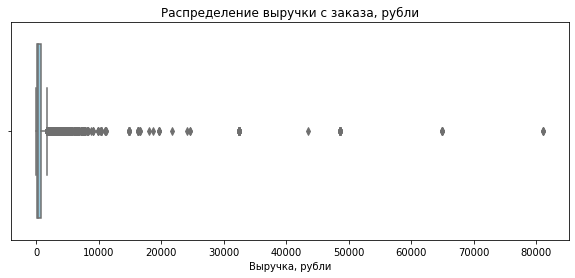

In [31]:
# Настройка размера графика
plt.figure(figsize=(10, 4))

# Строим горизонтальный боксплот 
sns.boxplot(x=df_rub['revenue'], color='skyblue')

# Настраиваем заголовки
plt.title('Распределение выручки с заказа, рубли')
plt.xlabel('Выручка, рубли')
plt.show()

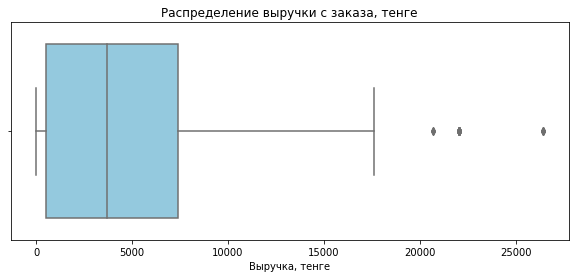

In [32]:
# Настройка размера графика
plt.figure(figsize=(10, 4))

# Строим горизонтальный боксплот 
sns.boxplot(x=df_kzt['revenue'], color='skyblue')

# Настраиваем заголовки
plt.title('Распределение выручки с заказа, тенге')
plt.xlabel('Выручка, тенге')
plt.show()

В рублях распределение выручки сильно скошено вправо: основная масса заказов сосредоточена около нуля, а выбросы тянутся до 81 000 руб. В тенге выбросов мало, распределение компактнее.

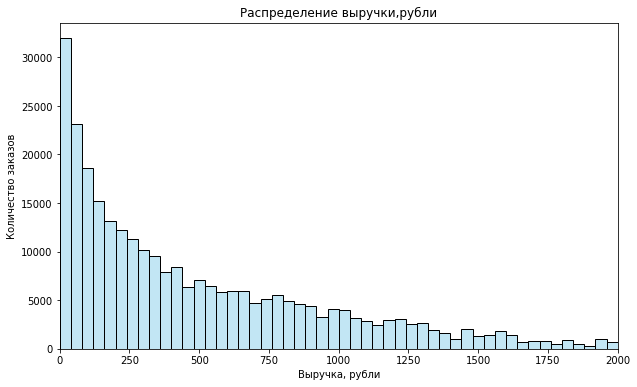

In [33]:
# График распределения значений
plt.figure(figsize=(10, 6))
# Строим гистограмму
sns.histplot(
    data=df_rub,x='revenue',
    bins=50,
    alpha=0.5,
    binrange=(0,2000),
    color='skyblue'
)
# Оформляем внешний вид
plt.title('Распределение выручки,рубли')
plt.xlabel('Выручка, рубли')
plt.ylabel('Количество заказов')
plt.xlim(0,2000)
plt.show()

In [34]:
# Заказы с выручкой более 2000 рублей
df_rub_over2000 = df_rub[df_rub['revenue'] > 2000]
print(f"Доля заказов с выручкой более 2000 RUB: {len(df_rub_over2000) / len(df_rub) * 100:.2f}%")                       

Доля заказов с выручкой более 2000 RUB: 2.45%


Распределение выручки в рублях сильно скошено вправо: большинство заказов приносит до нескольких сотен рублей, а число заказов падает с ростом выручки. График ограничен значением 2 000 руб., выше лежит 2.45% заказов.

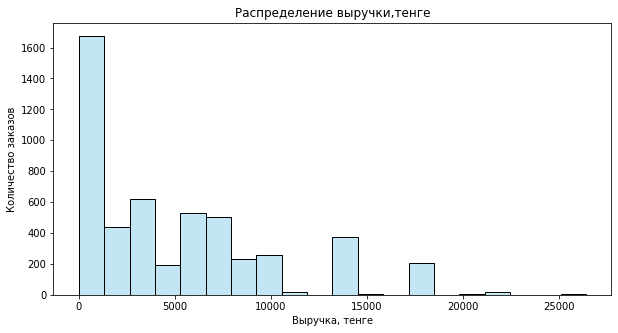

In [35]:
# График распределения значений
plt.figure(figsize=(10, 5))
# Строим гистограмму
sns.histplot(
    data=df_kzt,x='revenue',
    bins=20,
    alpha=0.5,
    color='skyblue'
)
# Оформляем внешний вид
plt.title('Распределение выручки,тенге')
plt.xlabel('Выручка, тенге')
plt.ylabel('Количество заказов')
plt.show()

Распределение выручки в тенге скошено вправо: больше всего заказов приходится на малые значения (до ~1 500 KZT), медиана около 3 700 KZT. Заметны отдельные всплески около 14 000 и 18 000 KZT, максимум около 26 400 KZT.

In [36]:
# Рассчитываем 99-й перцентиль для рублей и тенге
threshold_rub = df_rub['revenue'].quantile(0.99)
threshold_kzt = df_kzt['revenue'].quantile(0.99)

# Вывод результатов
print(f"99-й перцентиль (порог отсечения) для RUB: {threshold_rub:.2f}")
print(f"99-й перцентиль (порог отсечения) для KZT: {threshold_kzt:.2f}")


99-й перцентиль (порог отсечения) для RUB: 2570.80
99-й перцентиль (порог отсечения) для KZT: 17617.24


In [37]:
# Фильтруем: (Рубли И выручка <= 2570.80) ИЛИ (Тенге И выручка <= 17617.24)
tickets_orders_df = tickets_orders_df[
    ((tickets_orders_df['currency_code'] == 'rub') & (tickets_orders_df['revenue'] <= threshold_rub)) |
    ((tickets_orders_df['currency_code'] == 'kzt') & (tickets_orders_df['revenue'] <= threshold_kzt))
]

# Вывод результата после фильтрации аномалий
print(f"Размер таблицы после отсечения выбросов по 99-му процентилю: {len(tickets_orders_df)} строк")


Размер таблицы после отсечения выбросов по 99-му процентилю: 287639 строк


In [38]:
# Пересоздадим таблицу только с рублями с новым tickets_orders_df после отсечения выбросов по 99-му процентилю
df_rub = tickets_orders_df[tickets_orders_df['currency_code'] == 'rub']
# Вывод количества строк для рублей
print(f"Количество строк в таблице с рублями (RUB): {len(df_rub)}")

# Пересоздадим таблицу только с тенге с новым tickets_orders_df после отсечения выбросов по 99-му процентилю
df_kzt = tickets_orders_df[tickets_orders_df['currency_code'] == 'kzt']
# Вывод количества строк для тенге
print(f"Количество строк в таблице с тенге (KZT): {len(df_kzt)}")

Количество строк в таблице с рублями (RUB): 282599
Количество строк в таблице с тенге (KZT): 5040


Выбросы по выручке отсекались по 99-му процентилю отдельно для каждой валюты: порог 2 570,80 руб. и 17 617,24 KZT. Отсечено 2 800 заказов в рублях (около 0,98%) и 29 в тенге (около 0,57%); всего удалено 2 829 строк, осталось 287 639. В тенге отсечено меньше 1%, потому что на пороге лежит много заказов с одинаковой выручкой, и они сохранены. Отсечение выполнено, чтобы единичные дорогие заказы не искажали средние значения.

In [39]:
# Проверим полные дубликаты в tickets_orders_df
tickets_orders_df.duplicated().sum()

0

In [40]:
# Подсчет количества строк-повторов, которые подлежат удалению
duplicate_count = tickets_orders_df.duplicated(
    subset=[
        'user_id', 'created_dt_msk', 'created_ts_msk', 'event_id',
        'cinema_circuit', 'age_limit', 'currency_code',
        'device_type_canonical', 'revenue', 'service_name', 'tickets_count', 'total'
    ]
).sum()
# Выводим полученный результат на экран
print(f"Количество строк-повторов для удаления: {duplicate_count} шт.")


Количество строк-повторов для удаления: 39 шт.


Исключили `days_since_prev` потому что это вычисляемый столбец, и у настоящего повтора он был бы разным.

In [41]:
# Создаем логическую маску для поиска абсолютно всех копий (keep=False)
dup_mask = tickets_orders_df.duplicated(
    subset=[
        'user_id', 'created_dt_msk', 'created_ts_msk', 'event_id',
        'cinema_circuit', 'age_limit', 'currency_code',
        'device_type_canonical', 'revenue', 'service_name', 'tickets_count', 'total'
    ], 
    keep=False
)

# Применяем маску к датафрейму, сортируем и отбираем только нужные столбцы
columns_to_show = ['order_id', 'user_id', 'created_ts_msk', 'event_id', 'tickets_count', 'revenue', 'days_since_prev']
duplicates_df = tickets_orders_df[dup_mask].sort_values(by=['user_id', 'created_ts_msk'])[columns_to_show]

# Выводим первые строки для анализа
print("Строки со всеми найденными копиями заказов:")
print(duplicates_df.head(10))


Строки со всеми найденными копиями заказов:
       order_id          user_id       created_ts_msk  event_id  \
11777   1123983  06eb7897f65b433  2024-08-13 16:31:07    183706   
11778   1123867  06eb7897f65b433  2024-08-13 16:31:07    183706   
26894   1930705  0dc525d7bacbb0d  2024-07-31 13:26:11    393430   
26896   1930763  0dc525d7bacbb0d  2024-07-31 13:26:11    393430   
53715   1935113  206ea45ec11d478  2024-10-29 16:46:54    442183   
53717   1935171  206ea45ec11d478  2024-10-29 16:46:54    442183   
57217    160922  2564e3703075008  2024-10-30 10:04:15    589005   
57220    160893  2564e3703075008  2024-10-30 10:04:15    589005   
68214   3326185  2ecf0a4e24cae13  2024-10-17 15:25:33    481392   
68215   3326272  2ecf0a4e24cae13  2024-10-17 15:25:33    481392   

       tickets_count  revenue  days_since_prev  
11777              1    69.82              0.0  
11778              1    69.82              0.0  
26894              3  1556.05             11.0  
26896              3  

In [42]:
# Сохраним в переменную количество строк
rows_before=len(tickets_orders_df)

In [43]:
# Удаляем дубликаты заказов билетов по ключевым признакам
tickets_orders_df=tickets_orders_df.drop_duplicates(subset=[
        'user_id', 'created_dt_msk', 'created_ts_msk', 'event_id',
        'cinema_circuit', 'age_limit', 'currency_code',
        'device_type_canonical', 'revenue', 'service_name', 'tickets_count', 'total'
    ], 
    keep='first')
# Выводим результаты проверки
print(f"Количество строк было: {rows_before}")
print(f"Количество строк стало: {len(tickets_orders_df)}")
print(f"Удалено строк: {rows_before - len(tickets_orders_df)}")

Количество строк было: 287639
Количество строк стало: 287600
Удалено строк: 39


In [44]:
# Пересоздадим таблицу только с рублями с новым tickets_orders_df 
df_rub = tickets_orders_df[tickets_orders_df['currency_code'] == 'rub']
# Вывод количества строк для рублей
print(f"Количество строк в таблице с рублями (RUB): {len(df_rub)}")

# Пересоздадим таблицу только с тенге с новым tickets_orders_df 
df_kzt = tickets_orders_df[tickets_orders_df['currency_code'] == 'kzt']
# Вывод количества строк для тенге
print(f"Количество строк в таблице с тенге (KZT): {len(df_kzt)}")

Количество строк в таблице с рублями (RUB): 282561
Количество строк в таблице с тенге (KZT): 5039


Явных дубликатов в данных нет. Найдено 39 неявных дубликатов (около 0,01%): заказы, совпадающие по всем параметрам, включая секунду создания, и отличающиеся только `order_id`. `order_id` и вычисляемый `days_since_prev` в сравнение не включались. Дубликаты удалены, оставлено первое вхождение; осталось 287 600 строк.

In [45]:
# Выводим информацию о датафрейме
tickets_orders_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 287600 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               287600 non-null  int64  
 1   user_id                287600 non-null  object 
 2   created_dt_msk         287600 non-null  object 
 3   created_ts_msk         287600 non-null  object 
 4   event_id               287600 non-null  int64  
 5   cinema_circuit         287600 non-null  object 
 6   age_limit              287600 non-null  int64  
 7   currency_code          287600 non-null  object 
 8   device_type_canonical  287600 non-null  object 
 9   revenue                287600 non-null  float64
 10  service_name           287600 non-null  object 
 11  tickets_count          287600 non-null  int64  
 12  total                  287600 non-null  float64
 13  days_since_prev        265897 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

Корректировка типов данных

In [46]:
# Преобразовываем тип данных столбцов created_dt_msk и created_ts_msk из tickets_orders_df        
# к типу datetime64
tickets_orders_df['created_dt_msk'] = pd.to_datetime(tickets_orders_df['created_dt_msk'])
tickets_orders_df['created_ts_msk'] = pd.to_datetime(tickets_orders_df['created_ts_msk'])
# Преобразовываем тип данных столбца data к типу datetime64
tickets_tenge_df['data']=pd.to_datetime(tickets_tenge_df['data'])

In [47]:
# Находим минимальные и максимальные значения для проверки границ данных
cols_min = tickets_orders_df[['age_limit', 'tickets_count', 'order_id', 'event_id']].min()
cols_max = tickets_orders_df[['age_limit', 'tickets_count', 'order_id', 'event_id']].max()

# Выводим результаты анализа диапазонов 
for col in cols_min.index:
    print(f"Колонка '{col}':")
    print(f"  Минимум: {cols_min[col]}")
    print(f"  Максимум: {cols_max[col]}")
   

Колонка 'age_limit':
  Минимум: 0
  Максимум: 18
Колонка 'tickets_count':
  Минимум: 1
  Максимум: 57
Колонка 'order_id':
  Минимум: 1
  Максимум: 8653108
Колонка 'event_id':
  Минимум: 4436
  Максимум: 592325


In [48]:
# Преобразовываем типы данных с понижением разрядности
tickets_orders_df[['age_limit', 'tickets_count']] = tickets_orders_df[['age_limit', 'tickets_count']].astype('int8')
tickets_orders_df[['order_id', 'event_id']] = tickets_orders_df[['order_id', 'event_id']].astype('int32')

In [49]:
# Выводим информацию о датафрейме после преобразования
tickets_orders_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 287600 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   order_id               287600 non-null  int32         
 1   user_id                287600 non-null  object        
 2   created_dt_msk         287600 non-null  datetime64[ns]
 3   created_ts_msk         287600 non-null  datetime64[ns]
 4   event_id               287600 non-null  int32         
 5   cinema_circuit         287600 non-null  object        
 6   age_limit              287600 non-null  int8          
 7   currency_code          287600 non-null  object        
 8   device_type_canonical  287600 non-null  object        
 9   revenue                287600 non-null  float64       
 10  service_name           287600 non-null  object        
 11  tickets_count          287600 non-null  int8          
 12  total                  287600 non-null  floa

In [50]:
# Проверим минимальные и максимальные значения в данных
cols_min_type = tickets_orders_df[['age_limit', 'tickets_count', 'order_id', 'event_id']].min()
cols_max_type = tickets_orders_df[['age_limit', 'tickets_count', 'order_id', 'event_id']].max()

# Выводим результаты анализа диапазонов 
for col in cols_min_type.index:
    print(f"Колонка '{col}':")
    print(f"  Минимум: {cols_min_type[col]}")
    print(f"  Максимум: {cols_max_type[col]}")

Колонка 'age_limit':
  Минимум: 0
  Максимум: 18
Колонка 'tickets_count':
  Минимум: 1
  Максимум: 57
Колонка 'order_id':
  Минимум: 1
  Максимум: 8653108
Колонка 'event_id':
  Минимум: 4436
  Максимум: 592325


Столбцы с датами переведены в `datetime64`(`created_dt_msk`,`created_ts_msk` и `data`). Для целых столбцов понижена разрядность (`age_limit`, `tickets_count` в `int8`, `order_id`, `event_id` в `int32`), значения при этом не изменились. У дробных столбцов (`revenue`, `total`) типы остались без изменения, чтобы не терять точность при суммировании и усреднении. `days_since_prev` остаётся дробным из-за пропусков. Объём памяти `tickets_orders_df` снизился с 32,9 до 26,9 МБ.

Объединяем два датафрейма (`tickets_orders_df` и `tickets_events_df`) в `df` для удобства дальнейшего анализа

In [51]:
# Объединяем основной датафрейм с заказами и справочник мероприятий по уникальному ключу 'event_id'
# Используем левое соединение (how='left'), чтобы сохранить абсолютно все заказы из исходной таблицы
df=tickets_orders_df.merge(tickets_events_df,on='event_id',how='left')

# Проверяем количество строк после объединения
print(f"Количество строк после объединения: {len(df)}")

Количество строк после объединения: 287600


In [52]:
# Выводим количество пропущенных строк в датафрейме
df.isna().sum()

order_id                      0
user_id                       0
created_dt_msk                0
created_ts_msk                0
event_id                      0
cinema_circuit                0
age_limit                     0
currency_code                 0
device_type_canonical         0
revenue                       0
service_name                  0
tickets_count                 0
total                         0
days_since_prev           21703
event_name                  238
event_type_description      238
event_type_main             238
organizers                  238
region_name                 238
city_name                   238
city_id                     238
venue_id                    238
venue_name                  238
venue_address               238
dtype: int64

In [53]:
# Отбираем строки с пустыми значениями в колонке event_type_main
empty_events_df = df[df['event_type_main'].isna()]

print(len(empty_events_df))

238


In [54]:
# считаем значения cinema_circuit у заказов без мероприятия
cinema_check=empty_events_df['cinema_circuit'].value_counts(dropna=False)

# Смотрим результат
print(f"Значения cinema_circuit у заказов без мероприятия: \n {cinema_check}")

Значения cinema_circuit у заказов без мероприятия: 
 нет    238
Name: cinema_circuit, dtype: int64


In [55]:
# количество уникальных идентификаторов мероприятий
count_unique_events=empty_events_df['event_id'].nunique() 
print(f"Уникальных мероприятий среди заказов без данных: {count_unique_events}")

Уникальных мероприятий среди заказов без данных: 19


In [56]:
# Проверяем количество значений и пропусков для каждого столбца отдельно
for col in ['service_name', 'device_type_canonical']:
    print(f" Распределение для {col}")
    print(empty_events_df[col].value_counts(dropna=False))

 Распределение для service_name
Билеты без проблем    190
Билеты в руки          21
Лучшие билеты          21
Мой билет               4
Лови билет!             2
Name: service_name, dtype: int64
 Распределение для device_type_canonical
mobile     189
desktop     49
Name: device_type_canonical, dtype: int64


In [57]:
# Рассчитываем долю выручки от проблемных заказов в процентах
lost_revenue_share = (empty_events_df['revenue'].sum() / df['revenue'].sum()) * 100

# Выводим результат
print(f"Доля выручки потерянных заказов: {lost_revenue_share:.2f}%")

Доля выручки потерянных заказов: 0.00%


In [58]:
# Считаем количество строк с нулевой выручкой среди пустых событий
zero_revenue_count = (empty_events_df['revenue'] == 0).sum()

# Выводим результат
print(f"Количество заказов с нулевой выручкой: {zero_revenue_count}")

Количество заказов с нулевой выручкой: 211


У 238 заказов нет данных о мероприятии; у 211 из них нулевая выручка, поэтому доля выручки этих заказов 0,00%. Полностью удаляем из датафрейма все строки, у которых пропущено (равно NaN) значение в колонке event_type_main.

In [59]:
# Фильтруем датафрейм, оставляя только те строки, где заполнен основной тип мероприятия
# Удаляем записи с пропущенными значениями (NaN) в столбце 'event_type_main'
df=df[df['event_type_main'].notna()]

После объединения у 238 заказов (0,08%) нет данных о мероприятии: они относятся к 19 событиям, которых нет в tickets_events_df, и в основном (190 заказов) принадлежат одному оператору. Их доля в выручке менее 0,01%, отнести их к категории, региону или площадке невозможно, поэтому они удалены.

In [60]:
# Посмотрим общее количество строк (размер выборки) в датафрейме
len(df)

287362

In [61]:
# Подсчитываем количество пропущенных значений (NaN) в каждом столбце датафрейма
df.isna().sum()

order_id                      0
user_id                       0
created_dt_msk                0
created_ts_msk                0
event_id                      0
cinema_circuit                0
age_limit                     0
currency_code                 0
device_type_canonical         0
revenue                       0
service_name                  0
tickets_count                 0
total                         0
days_since_prev           21676
event_name                    0
event_type_description        0
event_type_main               0
organizers                    0
region_name                   0
city_name                     0
city_id                       0
venue_id                      0
venue_name                    0
venue_address                 0
dtype: int64

In [62]:
# Находим самую раннюю (минимальную) дату в столбце 'data'
check_data_min = tickets_tenge_df['data'].min()

# Находим самую позднюю (максимальную) дату в столбце 'data'
check_data_max = tickets_tenge_df['data'].max()

# Выводим временной интервал данных на экран в понятном текстовом формате
print(f"Дата начало: {check_data_min}, Дата окончания: {check_data_max}")


Дата начало: 2024-01-10 00:00:00, Дата окончания: 2024-12-31 00:00:00


In [63]:
# Объединяем основной датафрейм с таблицей курсов валют по дате создания заказа
# Используем левое соединение (how='left'), чтобы сохранить все строки из исходного df
df = df.merge(
    tickets_tenge_df[['data', 'curs']], 
    left_on='created_dt_msk', 
    right_on='data', 
    how='left'
)

# Проверяем количество строк после объединения, чтобы убедиться в отсутствии дублирования (размножения) строк
len(df)


287362

In [64]:
# Проверяем количество пропущенных значений (NaN) в столбце с курсом валют после объединения
df['curs'].isna().sum()

0

In [65]:
# Выводим общую системную информацию о датафрейме (типы данных, количество строк, память и пропуски)
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 287362 entries, 0 to 287361
Data columns (total 26 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                287362 non-null  int32         
 1   user_id                 287362 non-null  object        
 2   created_dt_msk          287362 non-null  datetime64[ns]
 3   created_ts_msk          287362 non-null  datetime64[ns]
 4   event_id                287362 non-null  int32         
 5   cinema_circuit          287362 non-null  object        
 6   age_limit               287362 non-null  int8          
 7   currency_code           287362 non-null  object        
 8   device_type_canonical   287362 non-null  object        
 9   revenue                 287362 non-null  float64       
 10  service_name            287362 non-null  object        
 11  tickets_count           287362 non-null  int8          
 12  total                   287362

In [66]:
# Находим минимальные значения для идентификаторов городов и площадок
min_city_venue = df[['city_id', 'venue_id']].min()

# Находим максимальные значения для идентификаторов городов и площадок
max_city_venue = df[['city_id', 'venue_id']].max()

# Выводим результаты анализа диапазонов 
for col in min_city_venue.index:
    print(f"Колонка '{col}':")
    print(f"Минимум: {min_city_venue[col]}")
    print(f"Максимум: {max_city_venue[col]}")

Колонка 'city_id':
Минимум: 2.0
Максимум: 37172.0
Колонка 'venue_id':
Минимум: 894.0
Максимум: 4677.0


In [67]:
# Преобразовываем типы данных с понижением разрядности
df['city_id'] = df['city_id'].astype('int32')
df['venue_id'] = df['venue_id'].astype('int16')

In [68]:
# Проверим общую информацию о датафрейме
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 287362 entries, 0 to 287361
Data columns (total 26 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                287362 non-null  int32         
 1   user_id                 287362 non-null  object        
 2   created_dt_msk          287362 non-null  datetime64[ns]
 3   created_ts_msk          287362 non-null  datetime64[ns]
 4   event_id                287362 non-null  int32         
 5   cinema_circuit          287362 non-null  object        
 6   age_limit               287362 non-null  int8          
 7   currency_code           287362 non-null  object        
 8   device_type_canonical   287362 non-null  object        
 9   revenue                 287362 non-null  float64       
 10  service_name            287362 non-null  object        
 11  tickets_count           287362 non-null  int8          
 12  total                   287362

In [69]:
# Создаем столбец revenue_rub на основе условия для тенге
df['revenue_rub'] = np.where(
    df['currency_code'] == 'kzt',        
    df['revenue'] * df['curs'] / 100,         # Значение для тенге (переводим по курсу)
    df['revenue']                       # Значение для рублей (оставляем как есть)
)

In [70]:
# Отбираем из df строки, где currency_code равен 'rub' 
df_rub = df[df['currency_code'] == 'rub']

# Сравниваем два столбца знаком != (получаем True/False, то есть «да/нет»)
# Считаем «да» (True) методом sum()
mismatches_count = (df_rub['revenue_rub'] != df_rub['revenue']).sum()

# Выводим результат на экран
print(f"Количество несовпадений у рублёвых заказов: {mismatches_count}")


Количество несовпадений у рублёвых заказов: 0


In [71]:
# Отбираем из df строки, где currency_code равен 'kzt'
df_kzt = df[df['currency_code'] == 'kzt']

# Находим максимальное значение выручки в рублях для заказов в тенге
max_revenue_rub = df_kzt['revenue_rub'].max()

# Выводим результат на экран
print(f"Максимальная выручка в рублях для заказов в KZT: {max_revenue_rub:.2f}")

Максимальная выручка в рублях для заказов в KZT: 3504.56


In [72]:
# Подсчитываем количество пропущенных значений (NaN) в столбце с выручкой в рублях
df['revenue_rub'].isna().sum()

0

In [73]:
# Проверим тип в столбце с выручкой в рублях
df['revenue_rub'].dtype

dtype('float64')

In [74]:
# Удаляем столбцы 'data' и 'curs' из датафрейма
df = df.drop(columns=['data', 'curs'])

In [75]:
# Рассчитываем стоимость одного билета в рублях
df['one_ticket_revenue_rub']=df['revenue_rub']/df['tickets_count']

In [76]:
# Извлекаем порядковый номер месяца (от 1 до 12) из даты создания заказа
df['month']=df['created_dt_msk'].dt.month

In [77]:
# Создаем словарь соответствия месяцев и сезонов
month_to_season = {
    1: 'зима', 2: 'зима', 12: 'зима',
    3: 'весна', 4: 'весна', 5: 'весна',
    6: 'лето', 7: 'лето', 8: 'лето',
    9: 'осень', 10: 'осень', 11: 'осень'
}

# Переводим номер месяца в название сезона с помощью метода map()
df['season'] = df['month'].map(month_to_season)


In [78]:
# Проверяем датафрейма в одном блоке вывода

print(f"1. Общее количество строк в датафрейме: {len(df):,}")

print("\n2. Распределение заказов по месяцам (month):")
print(df['month'].value_counts(dropna=False))

print("\n3. Распределение заказов по сезонам (season):")
print(df['season'].value_counts(dropna=False))

print("\n4. Проверяем 'revenue_rub':")
print(f" Тип данных: {df['revenue_rub'].dtype}")
print(f" Количество пропусков (NaN): {df['revenue_rub'].isna().sum()}")

print("\n5. Метрики для расчетной колонки 'one_ticket_revenue_rub':")
print(f" Тип данных: {df['one_ticket_revenue_rub'].dtype}")
print(f" Количество пропусков (NaN): {df['one_ticket_revenue_rub'].isna().sum()}")


1. Общее количество строк в датафрейме: 287,362

2. Распределение заказов по месяцам (month):
10    99156
9     69262
8     44529
7     40359
6     34056
Name: month, dtype: int64

3. Распределение заказов по сезонам (season):
осень    168418
лето     118944
Name: season, dtype: int64

4. Проверяем 'revenue_rub':
 Тип данных: float64
 Количество пропусков (NaN): 0

5. Метрики для расчетной колонки 'one_ticket_revenue_rub':
 Тип данных: float64
 Количество пропусков (NaN): 0


В ходе предобработки удалены возвраты (381 заказ), выбросы выручки (2 829), неявные дубликаты (39) и заказы без данных о мероприятии (238): всего 3 487 строк (1,2%), осталось 287 362. Типы данных приведены к `datetime` и уменьшены, датафреймы объединены в `df`, добавлены `revenue_rub`, `one_ticket_revenue_rub`, `month` и `season`. Заказы с нулевой выручкой сохранены для подсчёта заказов и исключаются только при расчёте выручки с билета.

## Исследовательский анализ данных


### Анализ распределения заказов по сегментам и их сезонные изменения


In [79]:
# Считаем общее количество заказов для каждого месяца
order_for_month=df.groupby(['month'])['order_id'].count().reset_index()
print(f"Количество заказов по месяцам:")
print(f"{order_for_month}")

Количество заказов по месяцам:
   month  order_id
0      6     34056
1      7     40359
2      8     44529
3      9     69262
4     10     99156


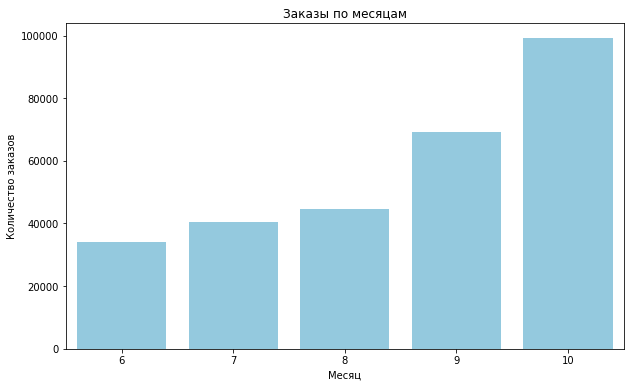

In [80]:
# График
plt.figure(figsize=(10,6))

sns.barplot(
    data=order_for_month,
    x='month',
    y='order_id',
    color='skyblue'
)

plt.title('Заказы по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.show()

In [81]:
# Проверяем последнюю дату в данных, чтобы понять, полный ли последний месяц
max_data = df['created_dt_msk'].max()

print(f"Самая поздняя дата в датафрейме: {max_data}")

Самая поздняя дата в датафрейме: 2024-10-31 00:00:00


In [82]:
# Рассчитываем процентное изменение количества заказов к предыдущему месяцу
order_for_month['pct'] = order_for_month['order_id'].pct_change() * 100

# Выводим результаты для проверки 
print("Процентное изменение количества заказов к предыдущему месяцу:")
print(order_for_month[['month', 'order_id', 'pct']].round(2).to_string(index=False))


Процентное изменение количества заказов к предыдущему месяцу:
 month  order_id   pct
     6     34056   NaN
     7     40359 18.51
     8     44529 10.33
     9     69262 55.54
    10     99156 43.16


Число заказов растёт каждый месяц: +18,5% в июле, +10,3% в августе, а затем резкое ускорение — +55,5% в сентябре и +43,2% в октябре. С июня по октябрь заказов стало почти втрое больше (34 056 → 99 156).

Изучим изменение пользовательской активности или пользовательского интереса в связи с сезонностью. 

Тип мероприятия: сумма долей -> лето 100.0, осень 100.0
season            лето  осень  diff_п.п.
event_type_main                         
выставки          2.02   1.43      -0.60
другое           27.08  19.64      -7.44
концерты         42.68  37.25      -5.43
спорт             2.52  11.20       8.67
стендап           5.34   4.11      -1.22
театр            20.13  25.37       5.24
ёлки              0.23   1.00       0.77
--------------------------------------------------
Тип устройства: сумма долей -> лето 100.0, осень 100.0
season                  лето  осень  diff_п.п.
device_type_canonical                         
desktop                19.38  20.36       0.98
mobile                 80.62  79.64      -0.98
--------------------------------------------------
Возрастное ограничение: сумма долей -> лето 100.0, осень 100.0
season      лето  осень  diff_п.п.
age_limit                         
0          17.88  23.58       5.69
6          18.21  17.62      -0.59
12         20.54  22.12    

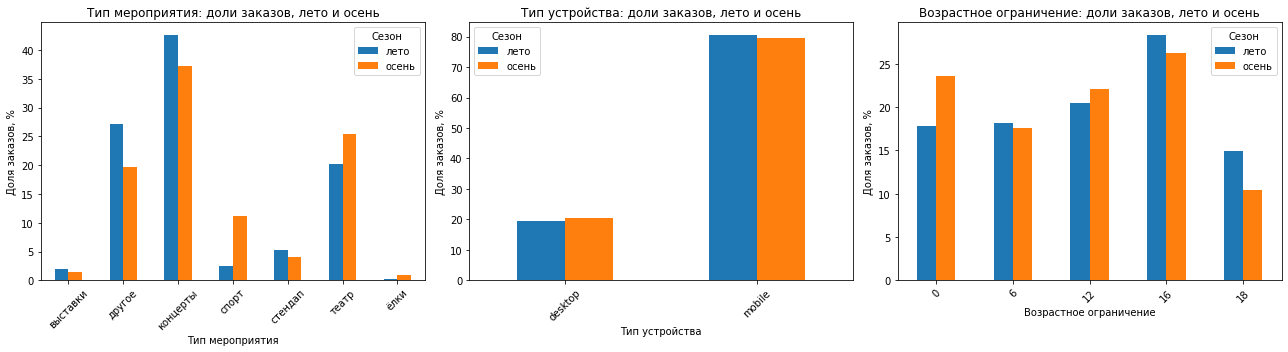

In [83]:
# Три разреза: столбец в df -> название для графика
segments = {
    'event_type_main': 'Тип мероприятия',
    'device_type_canonical': 'Тип устройства',
    'age_limit': 'Возрастное ограничение'
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (col, title) in zip(axes, segments.items()):
    # Количество заказов по сезону и категории
    counts = df.groupby(['season', col])['order_id'].count().reset_index(name='order_count')

    # Доля категории внутри своего сезона, %
    counts['share'] = counts['order_count'] / counts.groupby('season')['order_count'].transform('sum') * 100

    # Сводная таблица: строки - категории, столбцы - сезоны
    table = counts.pivot(index=col, columns='season', values='share').fillna(0)

    # Проверка: сумма долей в каждом сезоне должна быть 100
    print(f"{title}: сумма долей -> лето {table['лето'].sum():.1f}, осень {table['осень'].sum():.1f}")

    # Изменение доли осенью по сравнению с летом, в процентных пунктах
    table['diff_п.п.'] = table['осень'] - table['лето']
    print(table.round(2))
    print('-' * 50)

    # График: лето и осень рядом
    table[['лето', 'осень']].plot(kind='bar', ax=ax, rot=45)
    ax.set_title(f'{title}: доли заказов, лето и осень')
    ax.set_xlabel(title)
    ax.set_ylabel('Доля заказов, %')
    ax.legend(title='Сезон')

plt.tight_layout()
plt.show()

Осенью выросла доля спорта (+8,67 п.п.) и театра (+5,24 п.п.), а доля концертов (−5,43 п.п.) и категории «другое» (−7,44 п.п.) снизилась. Распределение по устройствам почти не изменилось (desktop +0,98 п.п.), заказы остаются преимущественно мобильными. По возрастам выросла доля 0+ (+5,69 п.п.) и снизилась доля 18+ (−4,55 п.п.).

In [84]:
# Берём только заказы с revenue_rub > 0
temp_df = df[df['revenue_rub'] > 0]

# Считаем среднюю выручку с билета в разрезе типов мероприятий и сезонов
mean_revenue = temp_df.groupby(['event_type_main', 'season'])['one_ticket_revenue_rub'].mean()

# Разворачиваем результат в таблицу «тип мероприятия × сезон»
table_revenue = mean_revenue.unstack(level='season')

# Считаем относительное изменение (осень к лету) в процентах и округляем
table_revenue['delta_autumn_summer_pct'] = (
    (table_revenue['осень'] - table_revenue['лето']) / table_revenue['лето'] * 100
).round(1)

# Проверяем размеры групп (число заказов для каждой пары)
group_sizes = temp_df.groupby(['event_type_main', 'season']).size().unstack(level='season')

# Выводим результаты для анализа
print("Средняя выручка с билета и изменение:")
print(table_revenue)
print("\nКоличество заказов по группам:")
print(group_sizes)


Средняя выручка с билета и изменение:
season                 лето       осень  delta_autumn_summer_pct
event_type_main                                                 
выставки          86.744476   91.905093                      5.9
другое            88.021277   77.421380                    -12.0
концерты         309.553830  268.421316                    -13.3
спорт             55.247119   50.245481                     -9.1
стендап          218.518107  231.124973                      5.8
театр            216.352713  176.084223                    -18.6
ёлки             271.436176  229.585589                    -15.4

Количество заказов по группам:
season            лето  осень
event_type_main              
выставки          2407   2402
другое           28477  32667
концерты         49984  62722
спорт             2762  18778
стендап           6346   6923
театр            23698  42707
ёлки               273   1691


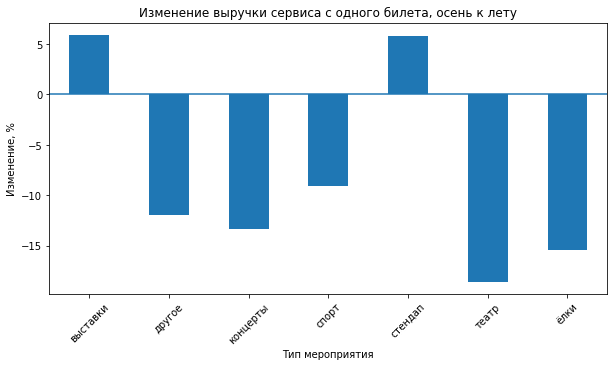

In [85]:
# Столбчатая диаграмма: изменение средней выручки с билета, осень к лету, %; линия на нуле отделяет рост от снижения
table_revenue['delta_autumn_summer_pct'].plot(kind='bar',
                                              figsize=(10, 5),
                                              title='Изменение выручки сервиса с одного билета, осень к лету',
                                              ylabel='Изменение, %',
                                              xlabel='Тип мероприятия',
                                              rot=45)
plt.axhline(0)
plt.show()
                            

Ёлки: летом всего 273 заказа (осенью 1 691). Группа маленькая, поэтому −15,4% менее надёжно, чем у остальных. 
Остальные группы большие (тысячи заказов), им можно доверять.
Cредняя выручка с билета выше всего у концертов (около 270-310 руб.), а у спорта ниже всего (около 50-55 руб.). Осенью доля концертов упала на 5,43 п.п., а доля спорта выросла на 8,67 п.п. 
Выручка сервиса с билета осенью снизилась у театра (−18,6%), ёлок (−15,4%), концертов (−13,3%), «другого» (−12,0%) и спорта (−9,1%), а выросла у выставок (+5,9%) и стендапа (+5,8%).

### Осенняя активность пользователей


In [86]:
# Фильтруем данные по осеннему сезону
autumn_df = df[df['season'] == 'осень']

# Группируем с использованием именованной агрегации
table_dats = autumn_df.groupby('created_dt_msk').agg(
    orders=('order_id', 'count'),
    dau=('user_id', 'nunique')
)

# Считаем количество заказов на одного активного пользователя
table_dats['order_per_user'] = table_dats['orders'] / table_dats['dau']

# Выводим первые строки и оцениваем размер таблицы
print(table_dats.head())
print(f"\nКоличество дней в выборке: {len(table_dats)}")


                orders  dau  order_per_user
created_dt_msk                             
2024-09-01        1327  564        2.352837
2024-09-02        1376  573        2.401396
2024-09-03        5094  777        6.555985
2024-09-04        1760  684        2.573099
2024-09-05        1941  738        2.630081

Количество дней в выборке: 61


In [87]:
# Фильтруем только заказы с положительной выручкой
positive_df = autumn_df[autumn_df['revenue_rub'] > 0]

# Считаем среднюю выручку с билета по каждому дню
grouped = (
    positive_df.groupby('created_dt_msk')['one_ticket_revenue_rub']
    .mean()
)

# Посмотрим на результат
print(grouped.head())

created_dt_msk
2024-09-01    202.149068
2024-09-02    190.847822
2024-09-03     80.713513
2024-09-04    179.567815
2024-09-05    189.902316
Name: one_ticket_revenue_rub, dtype: float64


In [88]:
# Записываем результат в новый столбец таблицы table_dats
table_dats['avg_ticket_revenue_rub']=grouped

# Посмотрим на итоговую таблицу с DAU, заказами и средней ценой билета
print(table_dats.head())

                orders  dau  order_per_user  avg_ticket_revenue_rub
created_dt_msk                                                     
2024-09-01        1327  564        2.352837              202.149068
2024-09-02        1376  573        2.401396              190.847822
2024-09-03        5094  777        6.555985               80.713513
2024-09-04        1760  684        2.573099              179.567815
2024-09-05        1941  738        2.630081              189.902316


In [89]:
# Проверим наличие пропусков
table_dats['avg_ticket_revenue_rub'].isna().sum()

0

In [90]:
# заказы за 3 сентября
day_df = autumn_df[autumn_df['created_dt_msk'] == '2024-09-03']

# сколько заказов у каждого пользователя в этот день (топ-5)
top_users = day_df['user_id'].value_counts().head()
print(top_users)

# доля заказов самого активного пользователя, %
print(top_users.iloc[0] / len(day_df) * 100)

# доля заказов с нулевой выручкой за день, %
print((day_df['revenue_rub'] == 0).mean() * 100)

0beb8fc0c0a9ce1    183
cdbc02c6ad8087a    169
4226e240b0f7a38    138
6191b67aadb9231    113
e35e526ac722993    109
Name: user_id, dtype: int64
3.5924617196702
0.07852375343541422


In [91]:
# Смотрим, какие типы мероприятий преобладают среди заказов 3 сентября (день пика) 
day_df['event_type_main'].value_counts() 

спорт       3692
концерты     568
другое       390
театр        374
стендап       55
выставки      11
ёлки           4
Name: event_type_main, dtype: int64

3 сентября зафиксирован всплеск: 5 094 заказа и 6,56 заказа на пользователя. Около 72,5% заказов этого дня (3 692) относятся к спорту, хотя в среднем за осень его доля около 11%. Среди пользователей нет доминирующего: самый активный оформил 183 заказа (3,59%), пятеро самых активных от 109 до 183. Низкая средняя выручка сервиса с билета в этот день (80,7 руб.) согласуется с тем, что у спорта она самая низкая; нулевых заказов почти нет (0,08%). Причину всплеска по данным установить нельзя; день оставлен в данных.

График 1: Заказы по дням

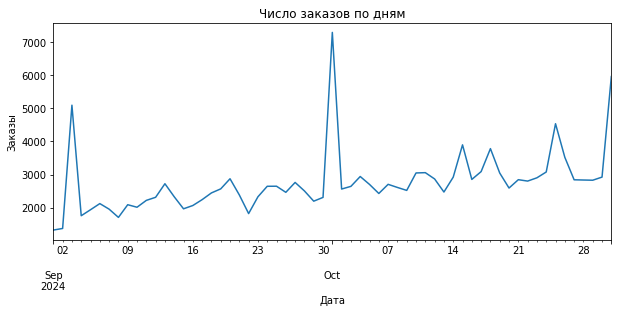

In [92]:
# Берём столбец с числом заказов и рисуем линию (по оси X - дата из индекса)
table_dats['orders'].plot(figsize=(10, 4), title='Число заказов по дням')
# Подписываем оси, чтобы было понятно, что на графике
plt.xlabel('Дата')
plt.ylabel('Заказы')
# Выводим график
plt.show()

График 2: DAU (уникальные пользователи за день)

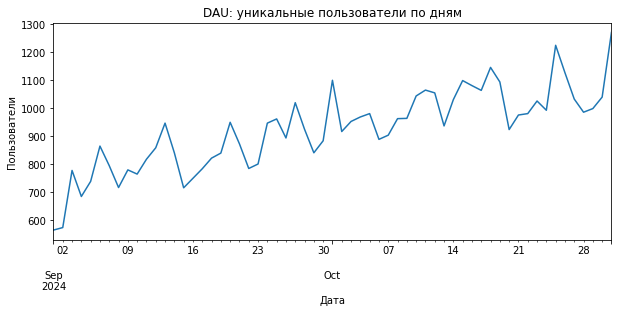

In [93]:
# Столбец с уникальными пользователями
table_dats['dau'].plot(figsize=(10, 4), title='DAU: уникальные пользователи по дням')
plt.xlabel('Дата')
plt.ylabel('Пользователи')
plt.show()

График 3: Заказов на одного пользователя

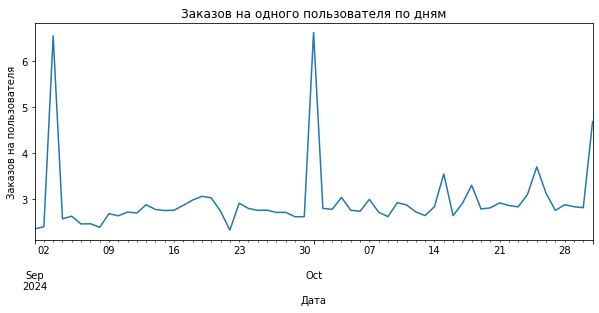

In [94]:
# Смотрим, сколько заказов в среднем оформляет один активный пользователь за день
table_dats['order_per_user'].plot(figsize=(10, 4), title='Заказов на одного пользователя по дням')
plt.xlabel('Дата')
plt.ylabel('Заказов на пользователя')
plt.show()

График 4: Средняя выручка с одного билета

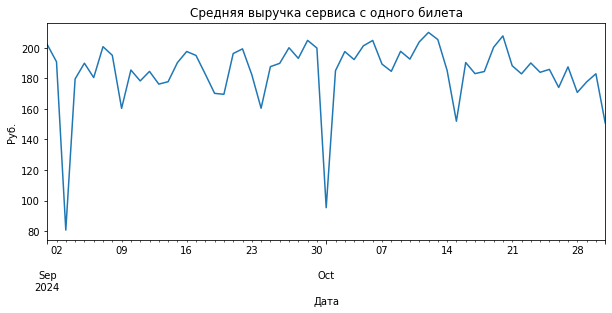

In [95]:
# Показывает, сколько в среднем зарабатывает сервис с одного билета за день
table_dats['avg_ticket_revenue_rub'].plot(figsize=(10, 4), title='Средняя выручка сервиса с одного билета')
plt.xlabel('Дата')
plt.ylabel('Руб.')
plt.show()

In [96]:
# Номер дня недели: 0 - понедельник, ..., 5 - суббота, 6 - воскресенье
# Выражение ">= 5" даёт True для выходных и False для будней
table_dats['weekend'] = table_dats.index.dayofweek >= 5

# Считаем медиану, чтобы два пиковых дня не искажали сравнение
print(table_dats.groupby('weekend')[['orders', 'dau', 'order_per_user', 'avg_ticket_revenue_rub']].median().round(2))

         orders    dau  order_per_user  avg_ticket_revenue_rub
weekend                                                       
False    2716.0  956.5            2.84                  184.56
True     2431.0  888.0            2.74                  200.31


In [97]:
# Находим точную дату пика 
peak_date = table_dats['orders'].idxmax()
print(f"Анализируем пиковую дату: {peak_date}\n")

# Отбираем строки за эту дату в DataFrame 
peak_day_df = autumn_df[autumn_df['created_dt_msk'] == peak_date]

# Считаем количество заказов по типам мероприятий
event_counts = peak_day_df['event_type_main'].value_counts()

print("Распределение заказов по типам мероприятий в день пика:")
print(event_counts)


Анализируем пиковую дату: 2024-10-01 00:00:00

Распределение заказов по типам мероприятий в день пика:
спорт       4849
концерты    1073
театр        687
другое       538
стендап      101
выставки      23
ёлки          18
Name: event_type_main, dtype: int64


Число заказов и DAU растут от сентября к октябрю (DAU примерно с 570 до 1 250), число заказов на пользователя держится около 2,5-3. Два резких пика заказов (3 сентября и 1 октября) образованы в основном спортивными мероприятиями (72,5% и 66,5% заказов дня) и сопровождаются падением выручки сервиса с билета до 80-95 руб. против 160-210 в обычные дни. В будни заказов и DAU в среднем больше, чем в выходные (медианы 2 716 против 2 431 заказов), заказов на пользователя почти одинаково (2,84 и 2,74), а выручка с билета выше в выходные (200 против 185 руб.); для сравнения использованы медианы, чтобы два пиковых дня не искажали результат.

### Популярные события и партнёры

In [98]:
# Группируем данные по регионам с помощью именованной агрегации
region_stats = df.groupby('region_name').agg(
    unique_events=('event_id', 'nunique'),
    orders=('order_id', 'count')
)

# Считаем доли в процентах от общего итога по всей таблице и округляем до 1 знака
total_events = df['event_id'].nunique()
total_orders = len(df)

region_stats['events_share_pct'] = ((region_stats['unique_events'] / total_events) * 100).round(1)
region_stats['orders_share_pct'] = ((region_stats['orders'] / total_orders) * 100).round(1)

# Сортируем по убыванию количества заказов, чтобы сразу видеть лидеров
region_stats = region_stats.sort_values(by='orders', ascending=False)

# Выводим результат
region_stats.head(10)


,unique_events,orders,events_share_pct,orders_share_pct
region_name,,,,
Каменевский регион,5935,89662,26.6,31.2
Североярская область,3798,43724,17.0,15.2
Широковская область,1225,16099,5.5,5.6
Медовская область,503,13891,2.3,4.8
Озернинский край,349,10405,1.6,3.6
Светополянский округ,1068,7486,4.8,2.6
Малиновоярский округ,165,6314,0.7,2.2
Речиновская область,701,6265,3.1,2.2
Солнечноземская область,521,6238,2.3,2.2


In [99]:
# Рассчитываем кумулятивную (накопленную) долю заказов
region_stats['cumulative_orders_share'] = region_stats['orders_share_pct'].cumsum()

# Посмотрим на итоговый результат
region_stats.head(10)


,unique_events,orders,events_share_pct,orders_share_pct,cumulative_orders_share
region_name,,,,,
Каменевский регион,5935,89662,26.6,31.2,31.2
Североярская область,3798,43724,17.0,15.2,46.4
Широковская область,1225,16099,5.5,5.6,52.0
Медовская область,503,13891,2.3,4.8,56.8
Озернинский край,349,10405,1.6,3.6,60.4
Светополянский округ,1068,7486,4.8,2.6,63.0
Малиновоярский округ,165,6314,0.7,2.2,65.2
Речиновская область,701,6265,3.1,2.2,67.4
Солнечноземская область,521,6238,2.3,2.2,69.6


In [100]:
# Создаем маску: True для регионов, чья доля заказов меньше 1%
small_regions_mask = region_stats['orders_share_pct'] < 1

# Считаем количество таких регионов (True приравнивается к 1)
count_regions = small_regions_mask.sum()

print(f"Количество регионов с долей заказов меньше 1%: {count_regions}")

Количество регионов с долей заказов меньше 1%: 62


In [101]:
# Регионы с наибольшим разнообразием мероприятий
top_by_events = region_stats.sort_values(by='unique_events', ascending=False)

# Выводим результат
top_by_events[['unique_events', 'orders', 'events_share_pct', 'orders_share_pct']].head(10)

,unique_events,orders,events_share_pct,orders_share_pct
region_name,,,,
Каменевский регион,5935,89662,26.6,31.2
Североярская область,3798,43724,17.0,15.2
Широковская область,1225,16099,5.5,5.6
Светополянский округ,1068,7486,4.8,2.6
Речиновская область,701,6265,3.1,2.2
Травяная область,683,5036,3.1,1.8
Горицветская область,551,5152,2.5,1.8
Серебринская область,541,5586,2.4,1.9
Яблоневская область,534,6120,2.4,2.1


Наибольшее разнообразие мероприятий — в Каменевском регионе (5 935), Североярской (3 798) и Широковской области (1 225).Мероприятия и заказы сильно сконцентрированы географически: Каменевский регион и Североярская область дают 46,4% заказов и 43,6% мероприятий, а 62 региона имеют долю заказов менее 1% каждый. Среди регионов с наибольшим разнообразием мероприятий выделяется Светополянский округ: на него приходится 4,8% мероприятий, но только 2,6% заказов.

In [102]:
# Общее число уникальных мероприятий во всём датафрейме
all_events = df['event_id'].nunique()

# Группировка и расчет базовых показателей
services_report = df.groupby('service_name').agg(
    unique_events=('event_id', 'nunique'),
    unique_regions=('region_name', 'nunique'),
    orders_count=('order_id', 'count'),
    total_revenue=('revenue_rub', 'sum')
)

# Сортировка по убыванию выручки (для корректного расчета накопленной доли)
services_report = services_report.sort_values(by='total_revenue', ascending=False)

# Расчет долей от общего итога
# Доля мероприятий считается от общего числа уникальных мероприятий: одно мероприятие
# может продаваться несколькими партнёрами, поэтому сумма долей больше 100%
services_report['events_share'] = (services_report['unique_events'] / all_events) * 100
services_report['orders_share'] = (services_report['orders_count'] / services_report['orders_count'].sum()) * 100
services_report['revenue_share'] = (services_report['total_revenue'] / services_report['total_revenue'].sum()) * 100

# Считаем кумулятивные доли
services_report['orders_cum_share'] = services_report['orders_share'].cumsum()
services_report['revenue_cum_share'] = services_report['revenue_share'].cumsum()

# Округляем столбцы до 1 знака
columns_to_round = [
    'events_share', 'orders_share', 'revenue_share',
    'orders_cum_share', 'revenue_cum_share'
]
services_report[columns_to_round] = services_report[columns_to_round].round(1)

services_report.head(10)

,unique_events,unique_regions,orders_count,total_revenue,events_share,orders_share,revenue_share,orders_cum_share,revenue_cum_share
service_name,,,,,,,,,
Билеты без проблем,4210,76,62631,2.432247e+07,18.9,21.8,16.3,21.8,16.3
Мой билет,1300,63,34439,2.204203e+07,5.8,12.0,14.8,33.8,31.1
Облачко,2335,59,26402,1.858861e+07,10.5,9.2,12.5,43.0,43.5
Лови билет!,4859,70,40764,1.667390e+07,21.8,14.2,11.2,57.2,54.7
Весь в билетах,855,52,16424,1.653235e+07,3.8,5.7,11.1,62.9,65.8
Билеты в руки,3517,68,40186,1.319416e+07,15.8,14.0,8.8,76.9,74.6
Край билетов,252,19,6109,6.405689e+06,1.1,2.1,4.3,79.0,78.9
Прачечная,1026,33,10222,4.746811e+06,4.6,3.6,3.2,82.5,82.1
Дом культуры,272,17,4412,4.358656e+06,1.2,1.5,2.9,84.1,85.0


Явные лидеры есть и среди регионов, и среди партнёров. Каменевский регион и Североярская область дают 46,4% заказов, а 62 региона имеют долю заказов менее 1% каждый, то есть образуют длинный хвост. Пять крупнейших партнёров дают 65,8% выручки, лидер — «Билеты без проблем» (16,3%); по числу мероприятий впереди «Лови билет!» (21,8%), но выручки у него меньше (11,2%)

## Статистический анализ данных

In [103]:
# Оставим только заказы с устройствами mobile и desktop
hyp_df = autumn_df[autumn_df['device_type_canonical'].isin(['mobile', 'desktop'])]

# Для каждого пользователя посчитаем, с каких устройств он заказывал
devices_per_user = hyp_df.groupby('user_id')['device_type_canonical'].nunique()

# Выводим общую статистику по количеству типов устройств на одного пользователя
print("Распределение пользователей по числу типов устройств:")
print(devices_per_user.value_counts())

Распределение пользователей по числу типов устройств:
1    12554
2     3249
Name: device_type_canonical, dtype: int64


По результату видим что 3 249 из 15 803 пользователей заказывали с обоих устройств.Исключаем их, чтобы сохранить независимость групп: тест сравнивает две разные группы людей, и если один человек входит и в mobile, и в desktop, выборки пересекаются. Исключённые пользователи, скорее всего, более активные, поэтому результат относится к аудитории, которая пользуется одним устройством.

In [104]:
# Находим ID пользователей, которые оформляли заказы более чем с одного типа устройства
both_users = devices_per_user[devices_per_user > 1].index

# Фильтруем датафрейм: исключаем пользователей из выборки
# Теперь каждый оставшийся пользователь строго закреплен только за одной группой (mobile или desktop)
hyp_df = hyp_df[~hyp_df['user_id'].isin(both_users)]

# Считаем, сколько уникальных пользователей осталось в очищенном датафрейме
remaining_users_count = hyp_df['user_id'].nunique()

# Пересчитываем количество устройств на пользователя для обновленных данных
check_devices_per_user = hyp_df.groupby('user_id')['device_type_canonical'].nunique()

# Находим максимальное количество устройств у одного пользователя
max_devices = check_devices_per_user.max()

# Выводим результаты проверки
print(f"Количество уникальных пользователей в hyp_df: {remaining_users_count} чел.")
print(f"Максимальное количество устройств на одного пользователя: {max_devices}")

Количество уникальных пользователей в hyp_df: 12554 чел.
Максимальное количество устройств на одного пользователя: 1


In [105]:
# Подсчитываем количество заказов для каждого пользователя внутри его типа устройства
orders_per_user = hyp_df.groupby(['user_id', 'device_type_canonical'])['order_id'].count().reset_index(name='orders')

# Выводим первые 10 строк таблицы на экран 
orders_per_user.head(10)

,user_id,device_type_canonical,orders
0,0005ca5e93f2cf4,mobile,1
1,000898990054619,mobile,2
2,000a55a418c128c,mobile,2
3,001e7037d013f0f,mobile,2
4,00245c702bc343e,mobile,2
5,0033403583a55ed,mobile,1
6,0033e08fba8d0c9,mobile,1
7,00345f897f95a34,mobile,3
8,003764d5339bb45,mobile,1
9,00377cfae7548b7,mobile,1


In [106]:
# Отбрасываем пропуски: они только у первых заказов пользователя за весь период
gap_per_user = (
    hyp_df.dropna(subset=['days_since_prev'])
    .groupby(['user_id', 'device_type_canonical'])['days_since_prev']
    .mean()
    .reset_index(name='mean_gap_days')
)

# Выводим первые 10 строк полученной таблицы на экран
gap_per_user.head(10)


,user_id,device_type_canonical,mean_gap_days
0,0005ca5e93f2cf4,mobile,75.000000
1,000898990054619,mobile,51.000000
2,000a55a418c128c,mobile,16.000000
3,001e7037d013f0f,mobile,43.500000
4,00245c702bc343e,mobile,27.500000
5,0033403583a55ed,mobile,20.000000
6,00345f897f95a34,mobile,17.666667
7,0040e12d70fae81,desktop,39.000000
8,00419e4b645bb44,mobile,10.333333
9,0062ac9536d57e3,mobile,15.200000


Время между заказами берётся из столбца days_since_prev, поэтому для первого осеннего заказа пользователя интервал считается до его предыдущего заказа, в том числе летнего. Пропуски есть только у первых заказов пользователя за весь период, их мы отбрасываем. Для гипотезы это допустимо: анализируются осенние заказы, а время между ними определяется по реальной истории покупок.

In [107]:
# РАЗМЕРЫ ГРУПП (Количество пользователей)

print("Количество пользователей в orders_per_user")
# Считаем, сколько уникальных клиентов в группе mobile, и в desktop
print(orders_per_user['device_type_canonical'].value_counts())
print("\n" + "="*50 + "\n")

print("Количество пользователей в gap_per_user")
# Считаем пользователей для интервалов 
print(gap_per_user['device_type_canonical'].value_counts())
print("\n" + "="*50 + "\n")

# ОПИСАТЕЛЬНЫЕ СТАТИСТИКИ

print("Статистика по количеству заказов (orders)")
# Группируем по устройству, выбираем столбец 'orders' и смотрим среднее, медиану, минимумы и максимумы
display(orders_per_user.groupby('device_type_canonical')['orders'].describe().round(2))
print("\n" + "="*50 + "\n")

print("Статистика по интервалам между заказами (mean_gap_days)")
# Группируем по устройству, выбираем столбец с днями и смотрим аналогичные метрики
display(gap_per_user.groupby('device_type_canonical')['mean_gap_days'].describe().round(2))

Количество пользователей в orders_per_user
mobile     10935
desktop     1619
Name: device_type_canonical, dtype: int64


Количество пользователей в gap_per_user
mobile     7052
desktop     894
Name: device_type_canonical, dtype: int64


Статистика по количеству заказов (orders)


,count,mean,std,min,25%,50%,75%,max
device_type_canonical,,,,,,,,
desktop,1619.0,1.97,3.06,1.0,1.0,1.0,2.0,56.0
mobile,10935.0,2.86,4.10,1.0,1.0,2.0,3.0,123.0




Статистика по интервалам между заказами (mean_gap_days)


,count,mean,std,min,25%,50%,75%,max
device_type_canonical,,,,,,,,
desktop,894.0,31.36,36.56,0.0,0.00,16.0,53.0,146.0
mobile,7052.0,25.25,30.21,0.0,2.87,14.0,36.0,148.0


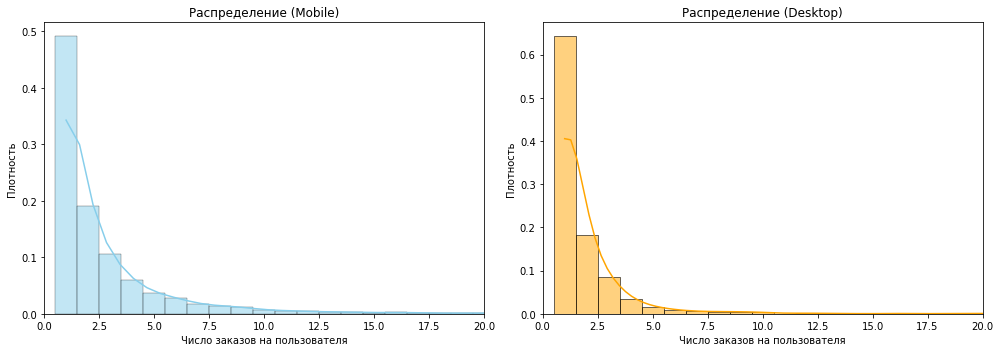

In [108]:
# Создаём 1 строку и 2 колонки
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Левый график — Mobile
sns.histplot(
    data=orders_per_user[orders_per_user['device_type_canonical'] == 'mobile'],
    x='orders',
    ax=axes[0],
    color='skyblue',
    stat='density',
    discrete=True,
    kde=True
)
axes[0].set_title('Распределение (Mobile)')
axes[0].set_xlabel('Число заказов на пользователя')
axes[0].set_ylabel('Плотность')
axes[0].set_xlim(0,20) # ось ограничена 20 заказами для читаемости,
                       # пользователи с большим числом заказов не показаны

# 2. Правый график — Desktop
sns.histplot(
    data=orders_per_user[orders_per_user['device_type_canonical'] == 'desktop'],
    x='orders',
    ax=axes[1],
    color='orange',
    stat='density',
    discrete=True,
    kde=True
)
axes[1].set_title('Распределение (Desktop)')
axes[1].set_xlabel('Число заказов на пользователя')
axes[1].set_ylabel('Плотность')
axes[1].set_xlim(0,20)
                   
plt.tight_layout()
plt.show()

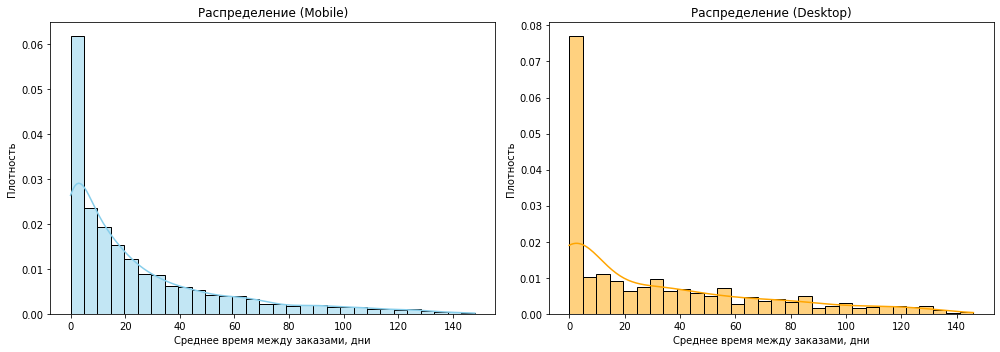

In [109]:
# Создаём 1 строку и 2 колонки
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Левый график — Mobile
sns.histplot(
    data=gap_per_user[gap_per_user['device_type_canonical'] == 'mobile'],
    x='mean_gap_days',
    ax=axes[0],
    color='skyblue',
    stat='density',
    bins=30,
    kde=True
)
axes[0].set_title('Распределение (Mobile)')
axes[0].set_xlabel('Среднее время между заказами, дни')
axes[0].set_ylabel('Плотность')

# 2. Правый график — Desktop
sns.histplot(
    data=gap_per_user[gap_per_user['device_type_canonical'] == 'desktop'],
    x='mean_gap_days',
    ax=axes[1],
    color='orange',
    stat='density',
    bins=30,
    kde=True
)
axes[1].set_title('Распределение (Desktop)')
axes[1].set_xlabel('Среднее время между заказами, дни')
axes[1].set_ylabel('Плотность')
                   
plt.tight_layout()
plt.show()

**Изучение данных перед тестами**

Для проверки гипотез данные агрегированы на уровне пользователя: для каждого пользователя посчитаны число заказов за осень и среднее время между заказами. Из выборки исключены 3 249 пользователей, заказывавших и с мобильных, и со стационарных устройств, чтобы группы не пересекались. Результаты относятся к аудитории, использующей одно устройство.

Группы существенно различаются по размеру: по числу заказов в `mobile` 10 935 пользователей, в `desktop` 1 619; по времени между заказами 7 052 и 894 соответственно. Распределения скошены вправо: среднее больше медианы (по заказам 2,86 при медиане 2 у `mobile` и 1,97 при медиане 1 у `desktop`), а максимумы очень велики (123 и 56 заказов). На графиках правый хвост виден в обеих метриках (у числа заказов ось ограничена 20 для читаемости, пользователи с большим числом заказов не показаны). Большинство пользователей делает 1–3 заказа, при этом у `desktop` доля пользователей с одним заказом выше. На графике интервалов есть пик у нуля: это пользователи, у которых заказы были в один день.

Время между заказами рассчитано по столбцу `days_since_prev`, поэтому для первого осеннего заказа пользователя интервал считается до его предыдущего заказа, в том числе летнего. Пропуски есть только у первых заказов за весь период, они исключены.

**Выбор теста**. Сравниваются две независимые группы по количественным метрикам. Выборки большие, поэтому среднее распределено близко к нормальному даже при скошенных данных, и подходит `t-тест` для двух независимых выборок. Из-за разного размера групп и разброса используем вариант `Уэлча (equal_var=False)`. Тесты односторонние, уровень значимости `0,05`.

**Гипотеза 1**. `H0`: среднее число заказов на пользователя у mobile и desktop одинаково. `H1`: у пользователей mobile оно выше.

**Гипотеза 2**. `H0`: среднее время между заказами у mobile и desktop одинаково. `H1`: у пользователей mobile оно выше.

In [110]:
# Гипотеза 1: среднее число заказов на пользователя, односторонний t-тест Уэлча
mobile_orders = orders_per_user[orders_per_user['device_type_canonical'] == 'mobile']['orders']
desktop_orders = orders_per_user[orders_per_user['device_type_canonical'] == 'desktop']['orders']

alpha = 0.05  # уровень значимости
results = stats.ttest_ind(mobile_orders, desktop_orders, equal_var=False, alternative='greater')


print('p-value:', results.pvalue)
print(f"Среднее число заказов: mobile = {mobile_orders.mean():.2f}, desktop = {desktop_orders.mean():.2f}")

# Сравниваем p-value с уровнем значимости
if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу: у mobile среднее значимо выше')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

p-value: 5.793910569768289e-25
Среднее число заказов: mobile = 2.86, desktop = 1.97
Отвергаем нулевую гипотезу: у mobile среднее значимо выше


Гипотеза 1 подтвердилась: среднее число заказов на пользователя у `mobile` (2,86) значимо выше, чем у `desktop` (1,97), `p-value` ≈ 5,8·10⁻²⁵ (< 0,05), нулевая гипотеза отвергнута. Разница в абсолютных значениях умеренная (около одного заказа за осень).

In [111]:
# Гипотеза 2: Среднее время между заказами, односторонний t-тест Уэлча
mobile_gap = gap_per_user[gap_per_user['device_type_canonical'] == 'mobile']['mean_gap_days']
desktop_gap = gap_per_user[gap_per_user['device_type_canonical'] == 'desktop']['mean_gap_days']

alpha = 0.05  # уровень значимости
results = stats.ttest_ind(mobile_gap, desktop_gap, equal_var=False, alternative='greater')


print('p-value:', results.pvalue)
print(f"Среднее время между заказами, дни: mobile = {mobile_gap.mean():.2f}, desktop = {desktop_gap.mean():.2f}")

# Сравниваем p-value с уровнем значимости
if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу: у mobile время между заказами значимо выше')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

p-value: 0.999999033706118
Среднее время между заказами, дни: mobile = 25.25, desktop = 31.36
Не получилось отвергнуть нулевую гипотезу


Гипотеза 2 не подтвердилась: среднее время между заказами у `mobile` (25,25 дня) не выше, а ниже, чем у `desktop` (31,36 дня), `p-value` ≈ 1, нулевая гипотеза не отвергнута. В выборке мобильные пользователи заказывают в среднем чаще, чем десктопные, но значимость этой разницы не проверялась. Время между заказами считалось по осенним заказам с учётом предыдущего заказа, в том числе летнего; из выборки исключены пользователи, заказывавшие с обоих типов устройств.

## Общий вывод и рекомендации

**Данные**. Использованы три датасета: заказы, мероприятия и курс тенге; из 290 849 заказов после предобработки осталось 287 362 (удалено 1,2%). Заказы билетов `Яндекс Афиши` за 01.06–31.10.2024 (после предобработки 287 362 заказа): удалены возвраты, выбросы выручки (99-й процентиль) и дубликаты, суммы в тенге переведены в рубли.

**Основные результаты**. Число заказов растёт каждый месяц (с 34 056 в июне до 99 156 в октябре), особенно сильно в сентябре (+55,5%) и октябре (+43,2%). Самая востребованная категория — концерты, но осенью их доля заказов снизилась на 5,43 п.п., а доля спорта (+8,67 п.п.) и театра (+5,24 п.п.) выросла. Средняя выручка сервиса с одного билета осенью снизилась почти по всем типам мероприятий, сильнее всего у театра (−18,6%). Пользовательская активность осенью растёт (DAU с ~570 до ~1 250); два пика заказов (3 сентября и 1 октября) связаны со спортивными мероприятиями с низкой выручкой с билета. Явные лидеры есть: Каменевский регион и Североярская область дают 46,4% заказов, пять крупнейших партнёров — 65,8% выручки (лидер — «Билеты без проблем»).

**Гипотезы**. Подтвердилась гипотеза о большем числе заказов у мобильных пользователей (2,86 против 1,97). Гипотеза о большем времени между заказами у `mobile` не подтвердилась: оно, наоборот, меньше (25,25 против 31,36 дня).

**Рекомендации**. 1) Подготовить предложение по спорту и театру на высокий сезон: именно эти категории растут осенью. 2) Следить за выручкой с билета: осенью она снизилась почти по всем типам мероприятий, а доля заказов на дешёвый спорт выросла. 3) Приоритет — мобильный опыт, потому что мобильные пользователи заказывают чаще. 4) Проверить причины пиков 3 сентября и 1 октября. 5) Опираться на двух региональных лидеров и пять крупнейших партнёров, не забывая про «длинный хвост».